# Kidney Stone Second Reader (v2)

**Pain point.** On a non-contrast CT for suspected renal colic, stones are tiny (median about 10 px in these slices) and often come in groups: more than half the slices hold two or more. The first stone is easy to see; the second and third are easy to miss, and a missed stone changes management.

**User.** The radiologist or ER doctor reading the scan, often on a night shift.

**What the user does with it.**
1. Opens a coronal slice.
2. Sees every candidate stone boxed and numbered, with a confidence score.
3. Accepts or rejects each box. **Red** boxes are right at least 9 times in 10. **Orange** boxes are less certain: *please look closer*.

The system is a **second reader**. It proposes; the doctor decides.

**What makes this project different.** The public split of this dataset puts slices from the same CT examination into both train and test. We split by scan session instead, so every test slice comes from an examination the model has never seen, and we score it the way a doctor would.

**Before you run.** Runtime → Change runtime type → **T4 GPU**. Put `kidney.zip` in `MyDrive/kidney_capstone/`. The first run trains the model (about 30 minutes). Later runs load the saved weights from Drive and skip training.

In [1]:
!pip -q install ultralytics gradio
from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.9 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
from pathlib import Path
import random, shutil, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DRIVE = Path('/content/drive/MyDrive/kidney_capstone')
WORK = Path('/content/work')
EPOCHS, IMGSZ, SEED = 60, 960, 0
NMS_IOU = 0.3               # merge overlapping boxes on one stone (the default 0.7 left stacks of duplicates)
MIN_IOU = 0.1               # a box also hits a stone when it overlaps it this much
TARGET_SENSITIVITY = 0.90   # show enough boxes to find 90% of validation stones
RED_PRECISION = 0.90        # a box is red only where boxes are right 90% of the time on validation
SESSION_GAP_S = 60          # slices acquired less than this many seconds apart belong to one scan session

DATA = WORK / 'kidney'
if not DATA.exists():
    with zipfile.ZipFile(DRIVE / 'kidney.zip') as z:
        z.extractall(WORK)

## 1. Data audit: what are we actually looking at?

Each file is one **slice**: a 2D coronal non-contrast CT crop around the kidneys, with boxes around every **stone**. Roboflow stored two augmented copies (flip, ±10° rotation) of every training slice, so we group files by their source UID first.

Slice UIDs carry the acquisition time (the 7th field starts with .NET ticks). Slices acquired seconds apart come from one CT examination: a **scan session**, our stand-in for a patient.

In [3]:
W, H = 391, 320  # every slice in this dataset has this size

def source_uid(path):
    return path.name.split('_png_jpg')[0]

def acquired_at(uid):
    # .NET ticks: 100 ns intervals since 0001-01-01
    return int(uid.split('-')[6][:18]) / 1e7

def read_stones(label_path):
    rows = [line.split() for line in Path(label_path).read_text().splitlines() if line.strip()]
    return [tuple(map(float, r[1:5])) for r in rows]

files = pd.DataFrame([
    {'uid': source_uid(p), 'rf_split': split, 'image': p, 'label': p.parent.parent / 'labels' / f'{p.stem}.txt'}
    for split in ['train', 'valid', 'test']
    for p in sorted((DATA / split / 'images').glob('*.jpg'))
])
assert files.groupby('uid').rf_split.nunique().max() == 1, 'a source slice appears in two Roboflow splits'

slices = (files.groupby('uid')
          .agg(rf_split=('rf_split', 'first'), images=('image', list), labels=('label', list))
          .reset_index())
slices['t'] = slices.uid.map(acquired_at)
slices = slices.sort_values('t').reset_index(drop=True)
slices['session'] = (slices.t.diff() > SESSION_GAP_S).cumsum()
slices['n_stones'] = slices.labels.map(lambda ls: len(read_stones(ls[0])))
train_sessions = set(slices.session[slices.rf_split == 'train'])
slices['leaked'] = (slices.rf_split != 'train') & slices.session.isin(train_sessions)

spanning = slices.groupby('session').rf_split.nunique().gt(1)
print(f'{len(files)} files = {len(slices)} unique slices from {slices.session.nunique()} scan sessions')
print(f'slices with no stone: {(slices.n_stones == 0).sum()}')
print(f'scan sessions spanning more than one Roboflow split: {spanning.sum()} of {len(spanning)}')
print('session count is stable across gap choices:',
      {gap: int((slices.t.diff() > gap).sum() + 1) for gap in [5, 30, 60, 120]})
display(slices.groupby('rf_split').agg(slices=('uid', 'size'), leaked_slices=('leaked', 'sum'), stones=('n_stones', 'sum')))

1300 files = 778 unique slices from 256 scan sessions
slices with no stone: 1
scan sessions spanning more than one Roboflow split: 93 of 256
session count is stable across gap choices: {5: 256, 30: 256, 60: 256, 120: 256}


,slices,leaked_slices,stones
rf_split,,,
test,123,68,224
train,532,0,1150
valid,123,68,325


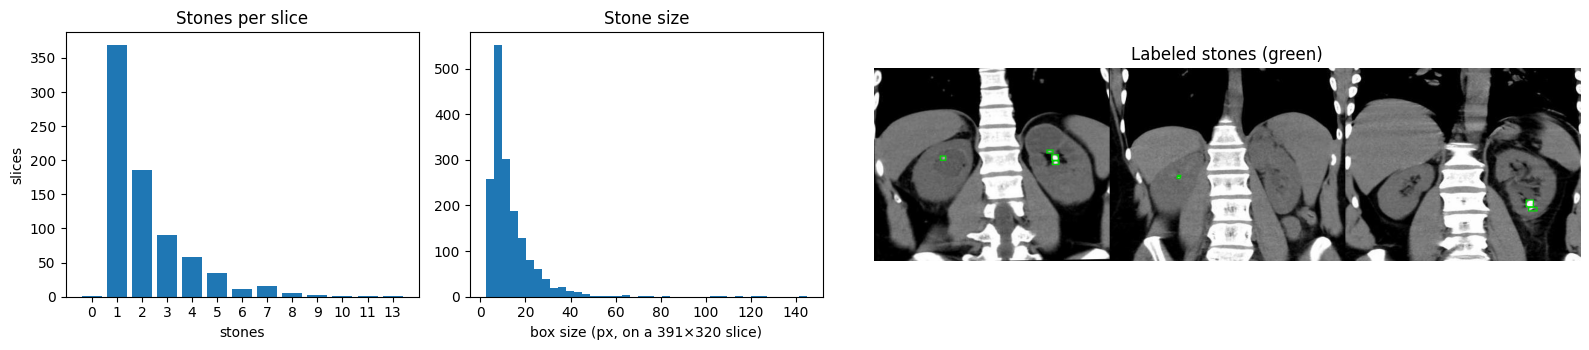

In [4]:
def to_px(box, size):
    cx, cy, w, h = box
    return ((cx - w / 2) * size[0], (cy - h / 2) * size[1], (cx + w / 2) * size[0], (cy + h / 2) * size[1])

def draw(image, stones=(), dets=(), red=1.0):
    """Green: labeled stones. Red: boxes at or above `red`. Orange: look closer. dets are (cx, cy, w, h, conf)."""
    im = image.convert('RGB')
    d = ImageDraw.Draw(im)
    for box in stones:
        d.rectangle(to_px(box, im.size), outline=(0, 220, 0), width=2)
    for i, (*box, conf) in enumerate(dets, 1):
        x0, y0, x1, y1 = to_px(box, im.size)
        color = (255, 40, 40) if conf >= red else (255, 165, 0)
        d.rectangle((x0 - 2, y0 - 2, x1 + 2, y1 + 2), outline=color, width=2)
        d.text((x1 + 3, y0 - 10), str(i), fill=color)
    return im

per_slice = slices.n_stones.value_counts().sort_index()
sizes_px = [np.sqrt(w * W * h * H) for ls in slices.labels for _, _, w, h in read_stones(ls[0])]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={'width_ratios': [1, 1, 2]})
ax[0].bar(per_slice.index.astype(str), per_slice.values); ax[0].set(title='Stones per slice', xlabel='stones', ylabel='slices')
ax[1].hist(sizes_px, bins=40); ax[1].set(title='Stone size', xlabel='box size (px, on a 391×320 slice)')
sample = slices[slices.n_stones >= 2].sample(3, random_state=SEED)
ax[2].imshow(np.hstack([np.asarray(draw(Image.open(r.images[0]), read_stones(r.labels[0]))) for r in sample.itertuples()]))
ax[2].set(title='Labeled stones (green)'); ax[2].axis('off')
plt.tight_layout(); plt.show()

## 2. Split by scan session

The published split was made per image, so 93 of 256 scan sessions have slices on both sides of it. A score on that test set partly measures memory of a patient the model already saw. We split by scan session instead (70/15/15): every validation and test slice comes from an examination the model never trained on.

*Earlier check (v1 run).* A model trained on the published split scored mAP50 0.781 on leaked test slices and 0.711 on clean ones, but stone sensitivity was the same (0.90 both) and the leaked slices are more crowded (2.1 stones per slice vs 1.4). So in this dataset the leak's measured effect is small and mixed up with difficulty. The session split is still the only one that answers the clinical question: *how does it do on a new patient?*

Training slices keep both augmented copies. Validation and test keep one copy per slice, so no slice is counted twice.

In [5]:
sessions = sorted(slices.session.unique())
random.Random(SEED).shuffle(sessions)
cut1, cut2 = int(0.70 * len(sessions)), int(0.85 * len(sessions))
session_split = {s: 'train' for s in sessions[:cut1]} | {s: 'valid' for s in sessions[cut1:cut2]} | {s: 'test' for s in sessions[cut2:]}
slices['split'] = slices.session.map(session_split)
assert not set(slices.session[slices.split == 'train']) & set(slices.session[slices.split != 'train'])

ROOT = WORK / 'split_session'
shutil.rmtree(ROOT, ignore_errors=True)
for split, group in slices.groupby('split'):
    for sub in ['images', 'labels']:
        (ROOT / split / sub).mkdir(parents=True)
    for r in group.itertuples():
        keep = len(r.images) if split == 'train' else 1
        for img, lab in list(zip(r.images, r.labels))[:keep]:
            shutil.copy(img, ROOT / split / 'images' / img.name)
            shutil.copy(lab, ROOT / split / 'labels' / lab.name)
DATA_YAML = ROOT / 'data.yaml'
DATA_YAML.write_text(f"path: {ROOT}\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: ['stone']\n")

val_rows, test_rows = slices[slices.split == 'valid'], slices[slices.split == 'test']
display(slices.groupby('split').agg(sessions=('session', 'nunique'), slices=('uid', 'size'), stones=('n_stones', 'sum')))

,sessions,slices,stones
split,,,
test,39,120,248
train,179,554,1221
valid,38,104,230


## 3. Train

YOLOv8s, pretrained on COCO. Changes from v1, all aimed at tiny stones:

* **960 px instead of 640.** A 10 px stone becomes about 25 px, so it spans several cells of the detector's finest grid instead of one or two.
* **Less zoom-out augmentation** (`scale=0.3`, default 0.5), so augmentation rarely shrinks a stone below what the detector can see.
* **Up to 60 epochs with early stopping** (`patience=20`): it stops when validation stops improving.

Training runs only when these weights are not already in Drive. The file name records the settings, so changing them retrains automatically.

In [6]:
from ultralytics import YOLO

WEIGHTS = DRIVE / f'model_session_split_{IMGSZ}px_{EPOCHS}ep.pt'
if not WEIGHTS.exists():
    trainer_model = YOLO('yolov8s.pt')
    trainer_model.train(data=str(DATA_YAML), epochs=EPOCHS, patience=20, imgsz=IMGSZ, batch=16, seed=SEED,
                        scale=0.3, degrees=10, cache='ram',
                        project=str(WORK / 'runs'), name='session_split', exist_ok=True)
    shutil.copy(trainer_model.trainer.best, WEIGHTS)
model = YOLO(str(WEIGHTS))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/split_session/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

In [7]:
def detections(rows):
    out = []
    for r in rows.itertuples():
        result = model.predict(str(r.images[0]), imgsz=IMGSZ, conf=0.001, iou=NMS_IOU, verbose=False)[0]
        for (cx, cy, w, h), conf in zip(result.boxes.xywhn.tolist(), result.boxes.conf.tolist()):
            out.append({'uid': r.uid, 'conf': conf, 'cx': cx, 'cy': cy, 'w': w, 'h': h})
    return pd.DataFrame(out, columns=['uid', 'conf', 'cx', 'cy', 'w', 'h'])

def map50():
    return model.val(data=str(DATA_YAML), split='test', imgsz=IMGSZ, iou=NMS_IOU, plots=False, verbose=False).box.map50

## 4. Evaluate the way a doctor would

* A **hit** is a box whose center falls inside a labeled stone, or that overlaps it by IoU ≥ 0.1. On a 6 px stone, a box shifted 3 px fails the usual IoU ≥ 0.5 test, yet any doctor would say *that's the stone*.
* Each box is one of three kinds: it **finds a stone** (the most confident box on that stone), it is a **duplicate** (a second box on a stone already found), or it is a **false alarm** (on no stone).
* **Stone sensitivity** is the share of labeled stones that got a box: *of all the stones there, how many did it point at?*
* **Boxes per slice** is everything the doctor has to look at. **False alarms per slice** is the part that points at nothing. **Precision** is the share of boxes that find a stone.
* **All stones found** is the share of slices where not a single stone was missed.
* Two thresholds, both chosen on *validation*, never on test:
  * **show** is the highest threshold that still finds 90% of validation stones. Boxes below it are hidden.
  * **red** is the lowest threshold where boxes above it find a stone at least 90% of the time. Boxes between *show* and *red* are orange.
* The 95% interval resamples whole scan sessions, because stones from one patient are not independent.
* **mAP50** is the standard ML metric (IoU ≥ 0.5), reported so the ML side is complete.

In [8]:
def stone_table(rows):
    return pd.DataFrame([{'uid': r.uid, 'session': r.session, 'cx': cx, 'cy': cy, 'w': w, 'h': h}
                         for r in rows.itertuples() for cx, cy, w, h in read_stones(r.labels[0])])

def match(stones, dets):
    """Adds stones.best_conf (most confident box on the stone, 0 if none) and dets.kind."""
    stones = stones.reset_index(drop=True)
    dets = dets.sort_values('conf', ascending=False).reset_index(drop=True)
    p = stones.reset_index().merge(dets.reset_index(), on='uid', suffixes=('_s', '_d'))
    dx, dy = (p.cx_d - p.cx_s).abs(), (p.cy_d - p.cy_s).abs()
    overlap_w = ((p.w_s + p.w_d) / 2 - dx).clip(lower=0).clip(upper=np.minimum(p.w_s, p.w_d))
    overlap_h = ((p.h_s + p.h_d) / 2 - dy).clip(lower=0).clip(upper=np.minimum(p.h_s, p.h_d))
    inter = overlap_w * overlap_h
    iou = inter / (p.w_s * p.h_s + p.w_d * p.h_d - inter)
    p = p[((dx <= p.w_s / 2) & (dy <= p.h_s / 2)) | (iou >= MIN_IOU)]
    stones['best_conf'] = p.groupby('index_s').conf.max().reindex(stones.index, fill_value=0.0)
    first = p.sort_values('index_d').drop_duplicates('index_s')
    dets['kind'] = 'false alarm'
    dets.loc[dets.index.isin(p.index_d), 'kind'] = 'duplicate'
    dets.loc[dets.index.isin(first.index_d), 'kind'] = 'finds a stone'
    return stones, dets

def at(stones, dets, n_slices, t):
    found, shown = stones.best_conf >= t, dets[dets.conf >= t]
    return {'threshold': t,
            'stone_sensitivity': found.mean(),
            'boxes_per_slice': len(shown) / n_slices,
            'false_alarms_per_slice': (shown.kind == 'false alarm').sum() / n_slices,
            'precision': (shown.kind == 'finds a stone').mean() if len(shown) else np.nan,
            'all_stones_found': found.groupby(stones.uid).all().mean()}

def show_threshold(stones, target):
    confs = np.sort(stones.best_conf.to_numpy())[::-1]
    k = int(np.ceil(round(target * len(confs), 6)))
    return max(confs[k - 1], 0.001)

def red_threshold(dets, target):
    precision = (dets.kind == 'finds a stone').cumsum() / np.arange(1, len(dets) + 1)
    ok = dets.conf.to_numpy()[precision.to_numpy() >= target]
    return float(ok.min()) if len(ok) else 1.0

def sensitivity_ci(stones, t, n=2000):
    per_session = stones.assign(found=stones.best_conf >= t).groupby('session').found.agg(['sum', 'size'])
    pick = np.random.default_rng(SEED).integers(0, len(per_session), (n, len(per_session)))
    rates = per_session['sum'].to_numpy()[pick].sum(1) / per_session['size'].to_numpy()[pick].sum(1)
    return np.percentile(rates, [2.5, 97.5])

val_stones, val_dets = match(stone_table(val_rows), detections(val_rows))
SHOW = show_threshold(val_stones, TARGET_SENSITIVITY)
RED = max(red_threshold(val_dets, RED_PRECISION), SHOW)
stones, dets = match(stone_table(test_rows), detections(test_rows))
print(f'show threshold {SHOW:.3f}: finds {(val_stones.best_conf >= SHOW).mean():.0%} of validation stones')
print(f'red threshold  {RED:.3f}: red boxes find a stone {at(val_stones, val_dets, len(val_rows), RED)["precision"]:.0%} of the time on validation')

results = []
for name, t in [('all boxes (red + orange)', SHOW), ('red boxes only', RED)]:
    lo, hi = sensitivity_ci(stones, t)
    results.append({'test set, unseen patients': name, **at(stones, dets, len(test_rows), t), 'sensitivity_95ci': f'{lo:.2f} to {hi:.2f}'})
results = pd.DataFrame(results).set_index('test set, unseen patients')
print(f'\nmAP50 on test: {map50():.3f}   ({len(test_rows)} slices, {len(stones)} stones, {test_rows.session.nunique()} scan sessions)')
display(results.round(3))

show threshold 0.089: finds 90% of validation stones
red threshold  0.321: red boxes find a stone 90% of the time on validation
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8.3±5.6 MB/s, size: 15.5 KB)
val: Scanning /content/work/split_session/test/labels... 120 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 1.4Kit/s 0.1s
val: New cache created: /content/work/split_session/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.6it/s 3.1s
                   all        120        248      0.797      0.666      0.632      0.224
Speed: 1.7ms preprocess, 18.7ms inference, 0.0ms loss, 0.8ms postprocess per image

mAP50 on test: 0.632   (120 slices, 248 stones, 39 scan sessions)


,threshold,stone_sensitivity,boxes_per_slice,false_alarms_per_slice,precision,all_stones_found,sensitivity_95ci
"test set, unseen patients",,,,,,,
all boxes (red + orange),0.089,0.931,2.083,0.133,0.812,0.908,0.88 to 0.98
red boxes only,0.321,0.879,1.683,0.008,0.941,0.825,0.83 to 0.93


Boxes per slice on test, by color and what they point at:


kind,duplicate,false alarm,finds a stone
color,,,
orange,0.17,0.12,0.11
red,0.09,0.01,1.58


Red boxes alone find 88% of stones; orange boxes add 5% more.


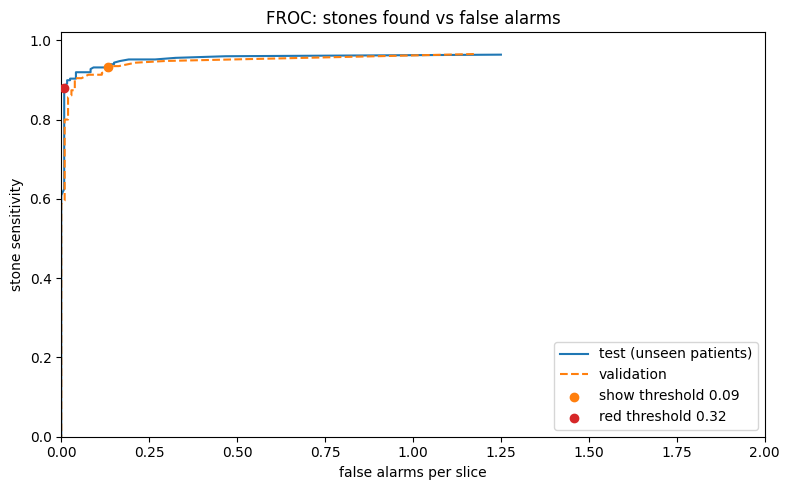

In [9]:
shown = dets[dets.conf >= SHOW].assign(color=lambda d: np.where(d.conf >= RED, 'red', 'orange'))
workload = (shown.groupby(['color', 'kind']).size() / len(test_rows)).unstack(fill_value=0)
print('Boxes per slice on test, by color and what they point at:')
display(workload.round(2))
print(f'Red boxes alone find {(stones.best_conf >= RED).mean():.0%} of stones; '
      f'orange boxes add {((stones.best_conf >= SHOW) & (stones.best_conf < RED)).mean():.0%} more.')

grid = np.linspace(0.001, 0.95, 200)
fig, ax = plt.subplots(figsize=(8, 5))
for label, (s, d, n), style in [('test (unseen patients)', (stones, dets, len(test_rows)), '-'),
                                ('validation', (val_stones, val_dets, len(val_rows)), '--')]:
    curve = pd.DataFrame([at(s, d, n, t) for t in grid])
    ax.plot(curve.false_alarms_per_slice, curve.stone_sensitivity, style, label=label)
for name, t, color in [('show', SHOW, 'tab:orange'), ('red', RED, 'tab:red')]:
    point = at(stones, dets, len(test_rows), t)
    ax.scatter(point['false_alarms_per_slice'], point['stone_sensitivity'], color=color, zorder=3, label=f'{name} threshold {t:.2f}')
ax.set(title='FROC: stones found vs false alarms', xlabel='false alarms per slice', ylabel='stone sensitivity', xlim=(0, 2), ylim=(0, 1.02))
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 5. Where does it fail?

Is it the small stones? Is it slices crowded with stones? Then look at the misses and the confident false alarms with your own eyes.

In [10]:
sized = stones.assign(size_px=np.sqrt(stones.w * W * stones.h * H), found=stones.best_conf >= SHOW)
sized['size_group'] = pd.qcut(sized.size_px.rank(method='first'), 3, labels=['small', 'medium', 'large'])
display(sized.groupby('size_group', observed=True)
        .agg(stones=('found', 'size'), median_px=('size_px', 'median'), stone_sensitivity=('found', 'mean')).round(2))
crowd = sized.groupby('uid').agg(n=('found', 'size'), all_found=('found', 'all'))
display(crowd.groupby(pd.cut(crowd.n, [0, 1, 2, 4, 99], labels=['1 stone', '2 stones', '3-4 stones', '5+ stones']), observed=True)
        .all_found.agg(slices='size', all_stones_found='mean').round(2))

,stones,median_px,stone_sensitivity
size_group,,,
small,83,6.48,0.84
medium,82,10.00,0.96
large,83,19.49,0.99


,slices,all_stones_found
n,,
1 stone,57,0.98
2 stones,33,0.94
3-4 stones,20,0.90
5+ stones,10,0.40


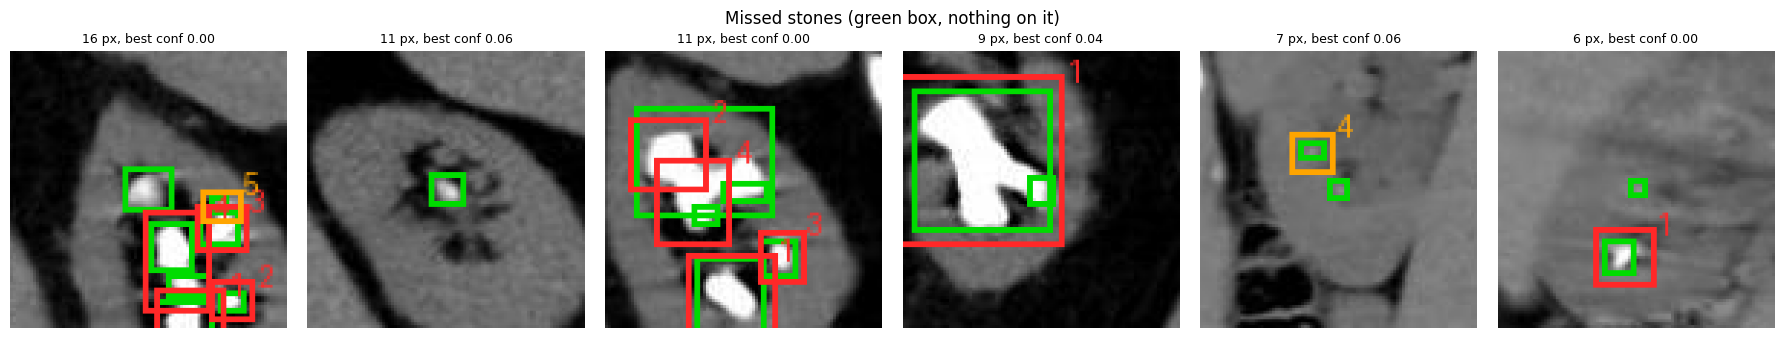

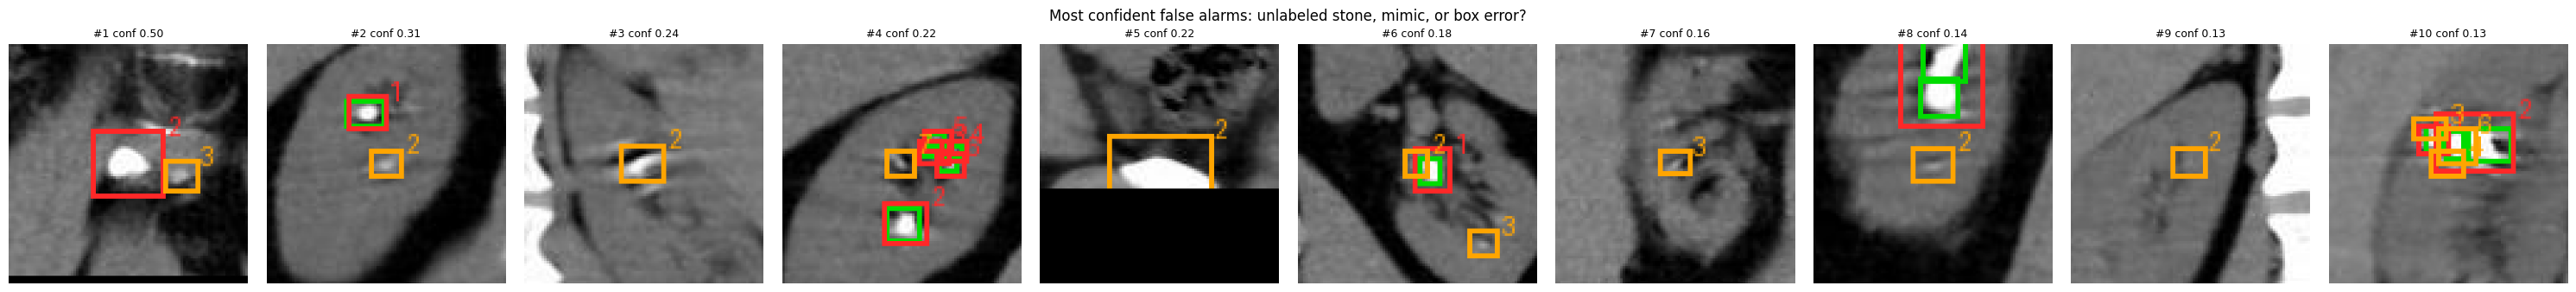

In [11]:
image_of = dict(zip(slices.uid, slices.images.str[0]))
label_of = dict(zip(slices.uid, slices.labels.str[0]))

def zoom(uid, box, half=48):
    """The slice around one box: labeled stones in green, boxes the doctor would see in red/orange."""
    on_slice = shown[shown.uid == uid]
    im = draw(Image.open(image_of[uid]), read_stones(label_of[uid]), on_slice[['cx', 'cy', 'w', 'h', 'conf']].itertuples(index=False), RED)
    x, y = box[0] * im.width, box[1] * im.height
    return im.crop((x - half, y - half, x + half, y + half)).resize((288, 288), Image.NEAREST)

def gallery(title, items):
    if not items:
        print(f'{title}: none'); return
    fig, axes = plt.subplots(1, len(items), figsize=(3 * len(items), 3.4), squeeze=False)
    for a, (img, caption) in zip(axes[0], items):
        a.imshow(img); a.set_title(caption, fontsize=9); a.axis('off')
    fig.suptitle(title); plt.tight_layout(); plt.show()

missed = sized[~sized.found].sort_values('size_px', ascending=False).head(6)
gallery('Missed stones (green box, nothing on it)',
        [(zoom(r.uid, (r.cx, r.cy)), f'{r.size_px:.0f} px, best conf {r.best_conf:.2f}') for r in missed.itertuples()])

false_alarms = shown[shown.kind == 'false alarm'].head(10)
gallery('Most confident false alarms: unlabeled stone, mimic, or box error?',
        [(zoom(r.uid, (r.cx, r.cy)), f'#{i} conf {r.conf:.2f}') for i, r in enumerate(false_alarms.itertuples(), 1)])

### Label audit

Look at each confident false alarm above and pick one category. **Not radiologist-verified.**

| Category | What it looks like |
|---|---|
| Unlabeled stone | Bright, round, inside the kidney's collecting system, but no green box. The model may be right and the label wrong. |
| Stone mimic | A **phlebolith** (calcified pelvic vein, often with a lucent center), a **vascular calcification** along an artery, bowel content, or bone. |
| Box error | The box sits next to a green box on the same stone, or the label boxes overlap each other. |

In [12]:
audit = false_alarms[['uid', 'conf']].assign(category='')  # fill in: unlabeled stone / stone mimic / box error
audit.index = range(1, len(audit) + 1)
display(audit)

,uid,conf,category
1,1-3-46-670589-33-1-63714778964016519000001-531...,0.502343,
2,1-3-46-670589-33-1-63706641772866810800001-494...,0.314262,
3,1-3-46-670589-33-1-63715469322363963500001-559...,0.240645,
4,1-3-46-670589-33-1-63706641772833809000001-547...,0.224346,
5,1-3-46-670589-33-1-63737665951748103300001-546...,0.218434,
6,1-3-46-670589-33-1-63724535887338560100001-510...,0.179116,
7,1-3-46-670589-33-1-63741210469056186100001-521...,0.160945,
8,1-3-46-670589-33-1-63714778964380539800001-570...,0.142216,
9,1-3-46-670589-33-1-63738808104478795000001-566...,0.132765,
10,1-3-46-670589-33-1-63737665951722101900001-498...,0.126843,


## 6. Medical interpretation

* **Stone sensitivity (all boxes).** Of every 100 stones on a new patient's slices, about this many get a box. The rest are misses the doctor must still catch alone.
* **Boxes and false alarms per slice.** How much the doctor has to look at, and how much of it points at nothing. Under about one false alarm per slice is tolerable for a second reader; several per slice trains the doctor to ignore the tool.
* **Red vs orange.** Red boxes are right at least 9 times in 10, so the doctor can trust them quickly. Orange boxes are where the second reader earns its keep: they catch the stones the confident boxes miss, at the cost of some false alarms.
* **All stones found.** For counting stones (single vs multiple), this matters more than per-stone sensitivity. One missed stone in a crowded kidney changes the count.
* **Size.** If small stones are missed most, the harm is limited: stones under about 5 mm usually pass on their own. A missed *large* stone is the dangerous error. Sizes here are in pixels, not mm, so this is only a trend.

## 7. Before this goes near a real clinic

1. **Specificity is unknown.** Every slice here contains a stone, so we cannot say how often it raises alarms on a healthy patient.
2. **One source.** All scans come from one center on one vendor (Philips), in Turkey, from 2019 to 2020. It needs external validation on other hospitals and scanners.
3. **2D, not 3D.** It sees single slices, while doctors scroll through the whole volume, and one stone spans several slices.
4. **No size in mm.** Pixel spacing was lost in export, so it cannot support decisions about whether a stone will pass or needs a procedure.
5. **Kidney crop only.** Ureteral stones, the ones most likely to cause colic, are out of scope.
6. **Noisy labels.** One unknown annotator, no radiologist consensus. Section 5 shows boxes the labels probably missed.
7. **Stone mimics.** Phleboliths and vascular calcifications can trigger false alarms.
8. **Automation bias and regulation.** Doctors may trust what the model misses. As clinical decision software it is a regulated medical device and needs approval before use.

## 8. Demo: the second reader

Upload a coronal slice or click an example. Red boxes are confident; orange boxes need a closer look. The slider starts at the *show* threshold; slide it up to the *red* threshold to see only confident boxes.

In [13]:
import gradio as gr

def second_reader(image, threshold):
    result = model.predict(image, imgsz=IMGSZ, conf=threshold, iou=NMS_IOU, verbose=False)[0]
    found = sorted(zip(result.boxes.xywhn.tolist(), result.boxes.conf.tolist()), key=lambda d: -d[1])
    dets = [(*box, conf) for box, conf in found]
    lines = [f'| {i} | {conf:.2f} | {"likely stone" if conf >= RED else "look closer"} |' for i, (*_, conf) in enumerate(dets, 1)]
    n_red = sum(conf >= RED for *_, conf in dets)
    report = (f'### {len(dets)} candidate stone(s): {n_red} red, {len(dets) - n_red} orange\n\n'
              '| # | confidence | flag |\n|---|---|---|\n' + '\n'.join(lines)
              + '\n\n_Second reader only. Every box needs confirmation by the reading doctor. No box does not mean no stone._')
    return draw(image, dets=dets, red=RED), report

examples = [[str(p), round(SHOW, 3)] for p in test_rows[test_rows.n_stones >= 2].images.str[0].head(4)]
gr.Interface(
    second_reader,
    [gr.Image(type='pil', label='Coronal non-contrast CT slice'),
     gr.Slider(0.001, 0.9, value=round(SHOW, 3), step=0.001,
               label=f'Confidence threshold (show = {SHOW:.3f}, red = {RED:.3f})')],
    [gr.Image(label='Candidate stones'), gr.Markdown()],
    examples=examples,
    title='Kidney Stone Second Reader',
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cb65d424c57397a938.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
